In [1]:
import pandas as pd

customers = pd.read_csv("../data/raw/olist_customers_dataset.csv")

In [2]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [3]:
customers.shape

(99441, 5)

In [4]:
customers.dtypes

customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str
dtype: object

In [5]:
customers.isna().sum()

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [6]:
customers.duplicated().sum()

np.int64(0)

In [7]:
customers["customer_id"].nunique(), customers["customer_unique_id"].nunique()

(99441, 96096)

In [8]:
orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")

In [9]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [10]:
orders.shape

(99441, 8)

In [11]:
orders.dtypes

order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

In [12]:
orders.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [13]:
orders.duplicated().sum()

np.int64(0)

In [14]:
orders["order_id"].nunique(), len(orders)

(99441, 99441)

In [15]:
orders[orders["order_delivered_customer_date"].isna()]["order_status"].value_counts()

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

In [16]:
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

orders.dtypes

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [17]:
tables = {
    "order_items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
}

for name, file in tables.items():
    df = pd.read_csv(f"../data/raw/{file}")
    print(name, df.shape)
    print("missing:", df.isna().sum().sum(), "| duplicates:", df.duplicated().sum())
    print(list(df.columns))
    print()

order_items (112650, 7)
missing: 0 | duplicates: 0
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

payments (103886, 5)
missing: 0 | duplicates: 0
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']

reviews (99224, 7)
missing: 145903 | duplicates: 0
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

products (32951, 9)
missing: 2448 | duplicates: 0
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']

sellers (3095, 4)
missing: 0 | duplicates: 0
['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state']

geolocation (1000163, 5)
missing: 0 | duplicates: 261831
['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_c

In [18]:
order_items = pd.read_csv("../data/raw/olist_order_items_dataset.csv")
payments = pd.read_csv("../data/raw/olist_order_payments_dataset.csv")
reviews = pd.read_csv("../data/raw/olist_order_reviews_dataset.csv")
products = pd.read_csv("../data/raw/olist_products_dataset.csv")
sellers = pd.read_csv("../data/raw/olist_sellers_dataset.csv")

print("order_items dup (order_id, order_item_id):", order_items.duplicated(["order_id", "order_item_id"]).sum())
print("payments dup (order_id, payment_sequential):", payments.duplicated(["order_id", "payment_sequential"]).sum())
print("reviews dup review_id:", reviews["review_id"].duplicated().sum())
print("reviews dup order_id:", reviews["order_id"].duplicated().sum())
print("products dup product_id:", products["product_id"].duplicated().sum())
print("sellers dup seller_id:", sellers["seller_id"].duplicated().sum())

print()
print(reviews.isna().sum())
print(products.isna().sum())

order_items dup (order_id, order_item_id): 0
payments dup (order_id, payment_sequential): 0
reviews dup review_id: 814
reviews dup order_id: 551
products dup product_id: 0
sellers dup seller_id: 0

review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


In [19]:
print(reviews.duplicated(["review_id", "order_id"]).sum())
print(reviews["order_id"].value_counts().head())

0
order_id
c88b1d1b157a9999ce368f218a407141    3
df56136b8031ecd28e200bb18e6ddb2e    3
03c939fd7fd3b38f8485a0f95798f1f6    3
8e17072ec97ce29f0e1f111e598b0c85    3
cf73e2cb1f4a9480ed70c154da3d954a    2
Name: count, dtype: int64


for ER diagram: 
Table customers {
  customer_id varchar [pk]
  customer_unique_id varchar
  customer_zip_code_prefix int
  customer_city varchar
  customer_state varchar
}

Table orders {
  order_id varchar [pk]
  customer_id varchar
  order_status varchar
  order_purchase_timestamp timestamp
  order_approved_at timestamp
  order_delivered_carrier_date timestamp
  order_delivered_customer_date timestamp
  order_estimated_delivery_date timestamp
}

Table order_items {
  order_id varchar
  order_item_id int
  product_id varchar
  seller_id varchar
  shipping_limit_date timestamp
  price numeric
  freight_value numeric
  indexes {
    (order_id, order_item_id) [pk]
  }
}

Table payments {
  order_id varchar
  payment_sequential int
  payment_type varchar
  payment_installments int
  payment_value numeric
  indexes {
    (order_id, payment_sequential) [pk]
  }
}

Table reviews {
  review_id varchar
  order_id varchar
  review_score int
  review_comment_title varchar
  review_comment_message varchar
  review_creation_date timestamp
  review_answer_timestamp timestamp
  indexes {
    (review_id, order_id) [pk]
  }
}

Table products {
  product_id varchar [pk]
  product_category_name varchar
  product_weight_g int
  product_length_cm int
  product_height_cm int
  product_width_cm int
}

Table sellers {
  seller_id varchar [pk]
  seller_zip_code_prefix int
  seller_city varchar
  seller_state varchar
}

Table category_translation {
  product_category_name varchar [pk]
  product_category_name_english varchar
}

Ref: orders.customer_id > customers.customer_id
Ref: order_items.order_id > orders.order_id
Ref: payments.order_id > orders.order_id
Ref: reviews.order_id > orders.order_id
Ref: order_items.product_id > products.product_id
Ref: order_items.seller_id > sellers.seller_id
Ref: products.product_category_name > category_translation.product_category_name

In [3]:
%pip install python-dotenv sqlalchemy "psycopg[binary]"

  Using cached python_dotenv-1.2.4-py3-none-any.whl.metadata (29 kB)
  Using cached sqlalchemy-2.1.6-cp314-cp314-win_amd64.whl.metadata (9.9 kB)
  Using cached psycopg-3.3.6-py3-none-any.whl.metadata (4.4 kB)
  Using cached psycopg_binary-3.3.6-cp314-cp314-win_amd64.whl.metadata (2.8 kB)
Using cached python_dotenv-1.2.4-py3-none-any.whl (23 kB)
Using cached sqlalchemy-2.1.6-cp314-cp314-win_amd64.whl (2.4 MB)
Using cached psycopg-3.3.6-py3-none-any.whl (215 kB)
Using cached psycopg_binary-3.3.6-cp314-cp314-win_amd64.whl (3.8 MB)

   ---------------------------------------- 0/4 [sqlalchemy]
   ---------------------------------------- 0/4 [sqlalchemy]
   ---------------------------------------- 0/4 [sqlalchemy]
   ---------------------------------------- 0/4 [sqlalchemy]
   ---------------------------------------- 0/4 [sqlalchemy]
   ---------------------------------------- 0/4 [sqlalchemy]
   ---------------------------------------- 0/4 [sqlalchemy]
   -----------------------------------


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import sys
import pandas as pd
sys.path.append("..")

from src.db import get_engine

engine = get_engine()

query = """
SELECT o.order_id, o.order_status, c.customer_state,
       o.order_purchase_timestamp,
       o.order_delivered_customer_date,
       o.order_estimated_delivery_date
FROM raw.orders o
JOIN raw.customers c ON o.customer_id = c.customer_id
"""

df = pd.read_sql(query, engine)
df.shape

(99441, 6)

In [5]:
import sys
print(sys.executable)

d:\projects\ecommerce-delivery-analysis\.venv\Scripts\python.exe


In [6]:
query = """
WITH items AS (
    SELECT order_id,
           SUM(price)         AS revenue,
           SUM(freight_value) AS freight,
           COUNT(*)           AS n_items
    FROM raw.order_items
    GROUP BY order_id
),
rev AS (
    SELECT order_id, AVG(review_score) AS review_score
    FROM raw.reviews
    GROUP BY order_id
)
SELECT o.order_id, o.order_status, c.customer_state,
       o.order_purchase_timestamp,
       o.order_delivered_customer_date,
       o.order_estimated_delivery_date,
       i.revenue, i.freight, i.n_items, r.review_score
FROM raw.orders o
JOIN raw.customers c ON o.customer_id = c.customer_id
LEFT JOIN items i ON o.order_id = i.order_id
LEFT JOIN rev r   ON o.order_id = r.order_id
"""

df = pd.read_sql(query, engine)
df.shape

(99441, 10)

In [7]:
from src.cleaning import clean_orders

orders_clean = clean_orders(df)

print(orders_clean.shape)
print(orders_clean["order_id"].is_unique)
print(orders_clean["delivery_days"].min())
print(orders_clean["is_late"].mean())
print(orders_clean["review_score"].isna().sum())

(96470, 14)
True
0.5334143518518518
0.08112366538820359
646


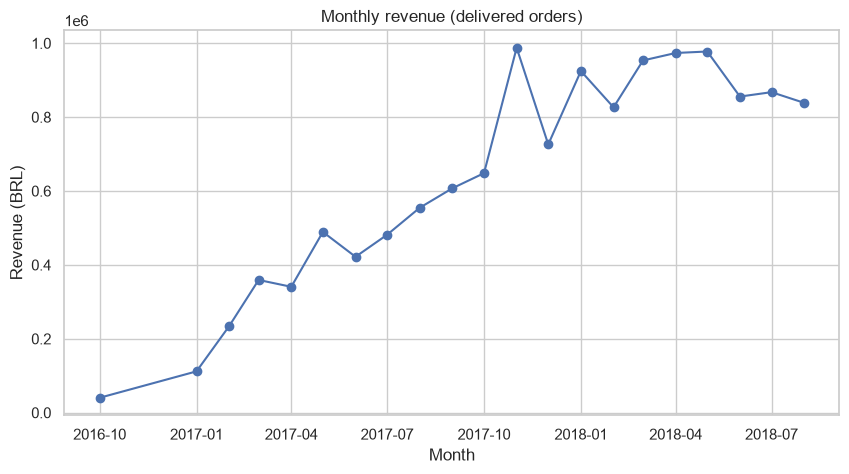

In [12]:
from src.plots import (
    monthly_revenue_chart, late_pct_by_state_chart,
    review_by_delivery_chart, review_by_delay_chart,
)

fig1 = monthly_revenue_chart(orders_clean)
fig1.savefig("../reports/monthly_revenue.png", dpi=150, bbox_inches="tight")


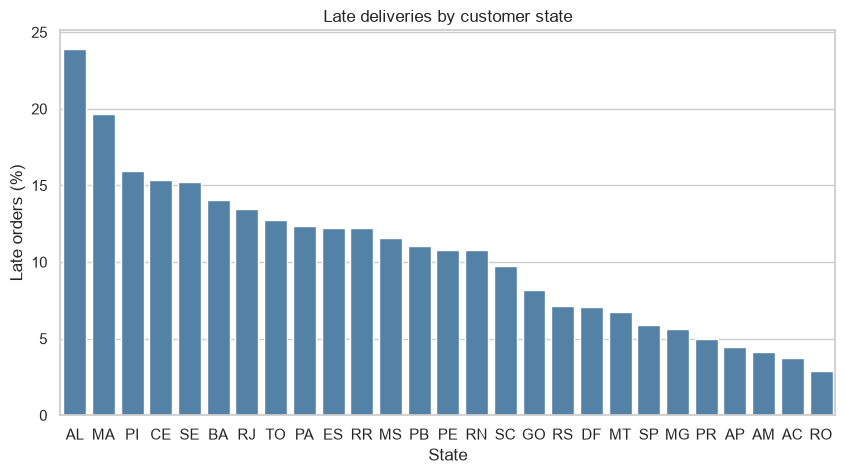

In [13]:
fig2 = late_pct_by_state_chart(orders_clean)
fig2.savefig("../reports/late_by_state.png", dpi=150, bbox_inches="tight")


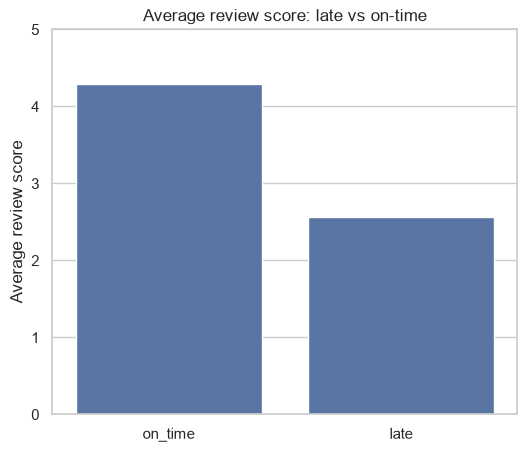

In [14]:
fig3 = review_by_delivery_chart(orders_clean)
fig3.savefig("../reports/review_late_vs_ontime.png", dpi=150, bbox_inches="tight")


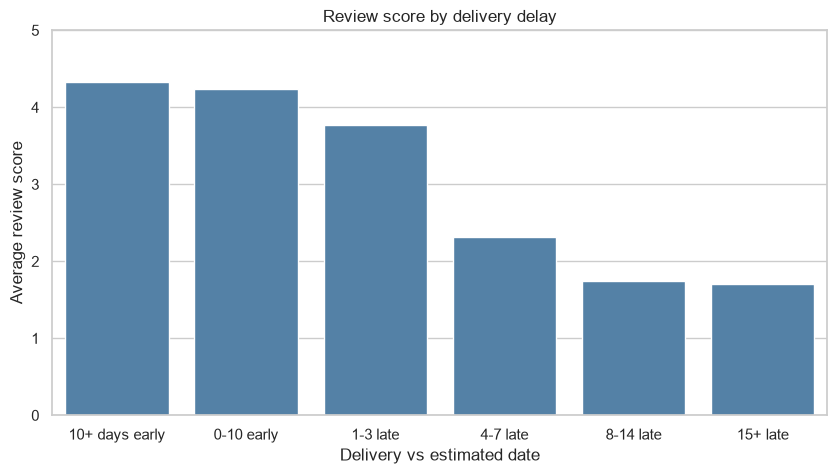

In [15]:
fig4 = review_by_delay_chart(orders_clean)
fig4.savefig("../reports/review_by_delay.png", dpi=150, bbox_inches="tight")


In [16]:
import numpy as np
from scipy import stats

data = orders_clean.dropna(subset=["review_score"])
late = data.loc[data["is_late"], "review_score"]
on_time = data.loc[~data["is_late"], "review_score"]

print("late:", len(late), "mean", round(late.mean(), 2), "median", late.median())
print("on_time:", len(on_time), "mean", round(on_time.mean(), 2), "median", on_time.median())

# Mann-Whitney U test
u_stat, p_mw = stats.mannwhitneyu(late, on_time, alternative="two-sided")
print("Mann-Whitney p-value:", p_mw)

# Welch t-test (does not assume equal spread)
t_stat, p_t = stats.ttest_ind(late, on_time, equal_var=False)
print("t-test p-value:", p_t)

# 95% confidence interval for the difference in means
diff = on_time.mean() - late.mean()
se = np.sqrt(late.var() / len(late) + on_time.var() / len(on_time))
print("Difference in means:", round(diff, 2))
print("95% CI:", round(diff - 1.96 * se, 2), "to", round(diff + 1.96 * se, 2))

late: 7661 mean 2.57 median 2.0
on_time: 88163 mean 4.29 median 5.0
Mann-Whitney p-value: 0.0
t-test p-value: 0.0
Difference in means: 1.73
95% CI: 1.69 to 1.77


In [17]:
from pathlib import Path

Path("../data/processed").mkdir(parents=True, exist_ok=True)

# Table 1: one row per delivered order
orders_clean.to_csv("../data/processed/orders.csv", index=False)

# Table 2: revenue by product category
category_sql = """
SELECT COALESCE(t.product_category_name_english, p.product_category_name, 'unknown') AS category,
       COUNT(DISTINCT o.order_id) AS orders,
       ROUND(SUM(i.price), 2)     AS revenue
FROM raw.order_items i
JOIN raw.orders o   ON i.order_id = o.order_id
JOIN raw.products p ON i.product_id = p.product_id
LEFT JOIN raw.category_translation t ON p.product_category_name = t.product_category_name
WHERE o.order_status = 'delivered'
GROUP BY 1
"""
pd.read_sql(category_sql, engine).to_csv("../data/processed/categories.csv", index=False)

# Table 3: revenue by seller
seller_sql = """
SELECT s.seller_id, s.seller_state,
       COUNT(DISTINCT o.order_id) AS orders,
       ROUND(SUM(i.price), 2)     AS revenue
FROM raw.order_items i
JOIN raw.orders o  ON i.order_id = o.order_id
JOIN raw.sellers s ON i.seller_id = s.seller_id
WHERE o.order_status = 'delivered'
GROUP BY 1, 2
"""
pd.read_sql(seller_sql, engine).to_csv("../data/processed/sellers.csv", index=False)

In [18]:
query = """
SELECT c.customer_unique_id, o.order_id, o.order_purchase_timestamp
FROM raw.orders o
JOIN raw.customers c ON o.customer_id = c.customer_id
WHERE o.order_status = 'delivered'
"""
cust = pd.read_sql(query, engine)

# Share of customers who ordered more than once
orders_per_customer = cust.groupby("customer_unique_id")["order_id"].nunique()
print("Customers:", len(orders_per_customer))
print("Repeat customers (%):", round((orders_per_customer > 1).mean() * 100, 1))

Customers: 93358
Repeat customers (%): 3.0


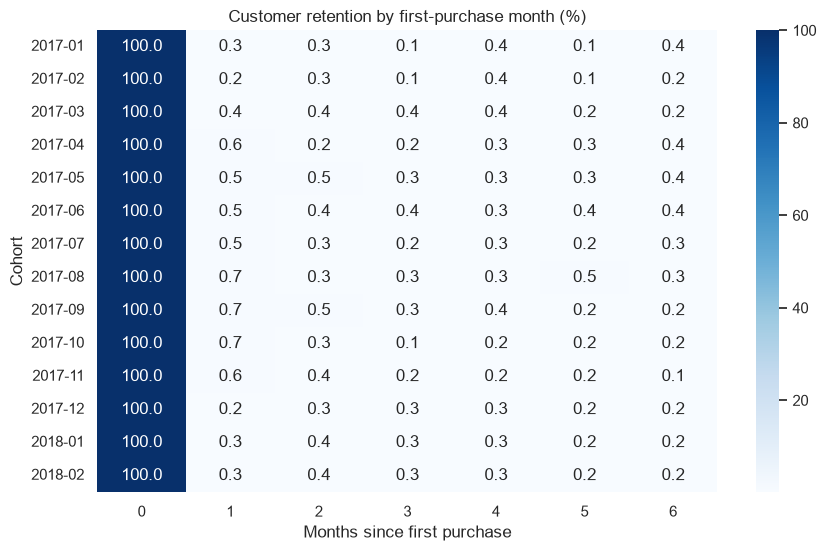

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

cust["order_month"] = pd.to_datetime(cust["order_purchase_timestamp"]).dt.to_period("M")

# Each customer's first month = their cohort
cust["cohort"] = cust.groupby("customer_unique_id")["order_month"].transform("min")

# Months between the order and the customer's first order
cust["months_since"] = (cust["order_month"] - cust["cohort"]).apply(lambda x: x.n)

# Unique customers per cohort and month
counts = (
    cust.groupby(["cohort", "months_since"])["customer_unique_id"]
    .nunique()
    .unstack(fill_value=0)
)

# Percent of the cohort still buying (month 0 = 100%)
retention = counts.div(counts[0], axis=0) * 100

# Keep cohorts with enough customers, and the first 6 months
retention = retention.loc["2017-01":"2018-02", 0:6]

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(retention.round(1), annot=True, fmt=".1f", cmap="Blues", ax=ax)
ax.set_title("Customer retention by first-purchase month (%)")
ax.set_xlabel("Months since first purchase")
ax.set_ylabel("Cohort")
fig.savefig("../reports/retention_heatmap.png", dpi=150, bbox_inches="tight")


In [21]:
# First order of each customer
first = cust.sort_values("order_purchase_timestamp").drop_duplicates("customer_unique_id")

# Add the late flag of that first order
first = first.merge(orders_clean[["order_id", "is_late"]], on="order_id", how="inner")

# Did the customer order again?
first["repeat"] = first["customer_unique_id"].map(orders_per_customer) > 1

print((first.groupby("is_late")["repeat"].mean() * 100).round(2))
print(first.groupby("is_late")["repeat"].size())

is_late
False    3.04
True     2.51
Name: repeat, dtype: float64
is_late
False    85746
True      7604
Name: repeat, dtype: int64


In [22]:
from scipy.stats import chi2_contingency

table = pd.crosstab(first["is_late"], first["repeat"])
chi2, p, dof, expected = chi2_contingency(table)
print(table)
print("p-value:", p)

repeat   False  True 
is_late              
False    83136   2610
True      7413    191
p-value: 0.010132886246234565


In [23]:
import numpy as np

d = orders_clean.dropna(subset=["review_score", "freight", "revenue"]).copy()
d = d[d["revenue"] > 0]
d["freight_ratio"] = d["freight"] / d["revenue"]   # shipping cost as a share of item price

cols = ["delivery_days", "freight", "freight_ratio", "review_score"]
print(d[cols].corr(method="spearman").round(2))

# Average score and late rate by freight group (5 equal-size groups)
d["freight_group"] = pd.qcut(d["freight_ratio"], 5, labels=["lowest", "low", "mid", "high", "highest"])
summary = d.groupby("freight_group", observed=True).agg(
    orders=("order_id", "count"),
    avg_score=("review_score", "mean"),
    late_pct=("is_late", lambda s: s.mean() * 100),
    avg_delivery_days=("delivery_days", "mean"),
).round(2)
print(summary)

               delivery_days  freight  freight_ratio  review_score
delivery_days           1.00     0.38           0.12         -0.23
freight                 0.38     1.00           0.10         -0.09
freight_ratio           0.12     0.10           1.00         -0.03
review_score           -0.23    -0.09          -0.03          1.00
               orders  avg_score  late_pct  avg_delivery_days
freight_group                                                
lowest          19165       4.20      8.08              11.47
low             19165       4.18      7.85              11.99
mid             19165       4.16      7.48              12.29
high            19175       4.13      8.28              13.07
highest         19154       4.11      8.29              13.76


In [25]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, classification_report
from sklearn.inspection import permutation_importance

m = orders_clean.copy()
m["purchase_month"] = m["order_purchase_timestamp"].dt.month
m["purchase_weekday"] = m["order_purchase_timestamp"].dt.dayofweek
m["customer_state"] = m["customer_state"].astype("category")

features = ["customer_state", "freight", "revenue", "n_items",
            "estimated_days", "purchase_month", "purchase_weekday"]

# Time-based split: train on the older 80%, test on the newest 20%
m = m.sort_values("order_purchase_timestamp")
cut = int(len(m) * 0.8)
train, test = m.iloc[:cut], m.iloc[cut:]

model = HistGradientBoostingClassifier(
    categorical_features="from_dtype", class_weight="balanced", random_state=42
)
model.fit(train[features], train["is_late"])

proba = model.predict_proba(test[features])[:, 1]
pred = proba > 0.5

print("ROC AUC:", round(roc_auc_score(test["is_late"], proba), 3))
print(classification_report(test["is_late"], pred))

imp = permutation_importance(
    model, test[features], test["is_late"], scoring="roc_auc", n_repeats=3, random_state=42
)
print(pd.Series(imp.importances_mean, index=features).sort_values(ascending=False).round(3))


C:\Users\SIBA\AppData\Local\Temp\ipykernel_15984\568541259.py:7: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  m["purchase_weekday"] = m["order_purchase_timestamp"].dt.dayofweek


ROC AUC: 0.701
              precision    recall  f1-score   support

       False       0.95      0.87      0.91     18273
        True       0.08      0.19      0.11      1021

    accuracy                           0.83     19294
   macro avg       0.51      0.53      0.51     19294
weighted avg       0.90      0.83      0.86     19294

estimated_days      0.254
customer_state      0.028
n_items             0.007
purchase_weekday    0.003
purchase_month      0.001
freight            -0.002
revenue            -0.009
dtype: float64
